# North American Wildlife Model Evaluation

This notebook evaluates the local 26-class North American wildlife detector against the `wildlife_very_dark` test split. Non-North-American, unsupported, and taxonomically ambiguous labels are reported but excluded from accuracy metrics.

The dataset has image-level labels rather than bounding boxes, so the notebook reports image-level detection and top-1 rates, not object-detection mAP.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_from_disk
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model_services.image import WildlifeDetector  # noqa: E402

DATASET_PATH = PROJECT_ROOT / 'data/datasets/wildlife_very_dark'
REPORT_PATH = PROJECT_ROOT / 'notebooks/results/wildlife_very_dark_report.json'
CONFIDENCE = 0.25
BATCH_SIZE = 16

print(f'Project: {PROJECT_ROOT}')
print(f'CUDA available: {torch.cuda.is_available()}')
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print(f'Device: {device_name}')

/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /home/vivek/Documents/Vivek-projects/WildGuard
CUDA available: True
Device: NVIDIA GeForce RTX 4090


## Evaluation policy

`wolf` has an exact model-class match. Bear, hare, and deer use explicitly labeled coarse proxies because the dataset label is broader than the model taxonomy. Fox is excluded because the model only supports swift fox and the dataset does not identify the fox species.

In [2]:
IN_SCOPE = {
    'wolf': {'gray_wolf'},
    'bear': {'black_bear', 'grizzly_bear'},
    'hare': {'jackrabbit'},
    'deer': {'mule_deer'},
}
MATCH_TYPE = {
    'wolf': 'exact_species',
    'bear': 'coarse_proxy',
    'hare': 'coarse_proxy',
    'deer': 'coarse_proxy',
}
EXCLUDED_REASONS = {
    'tiger': 'non_north_american',
    'lion': 'non_north_american',
    'hyena': 'non_north_american',
    'leopard': 'non_north_american',
    'antelope': 'ambiguous_likely_non_north_american',
    'raccoon': 'north_american_but_unsupported',
    'fox': 'ambiguous_species_model_only_supports_swift_fox',
}

dataset = load_from_disk(DATASET_PATH)
test_split = dataset['test']
label_counts = Counter(test_split['labels'])
policy_rows = []
for label, count in sorted(label_counts.items()):
    policy_rows.append({
        'label': label,
        'images': count,
        'status': 'evaluated' if label in IN_SCOPE else 'excluded',
        'reason_or_match': (
            MATCH_TYPE[label]
            if label in IN_SCOPE
            else EXCLUDED_REASONS.get(label, 'unmapped')
        ),
    })
policy_df = pd.DataFrame(policy_rows)
display(policy_df)

,label,images,status,reason_or_match
0,antelope,6,excluded,ambiguous_likely_non_north_american
1,bear,78,evaluated,coarse_proxy
2,deer,26,evaluated,coarse_proxy
3,fox,87,excluded,ambiguous_species_model_only_supports_swift_fox
4,hare,74,evaluated,coarse_proxy
5,hyena,62,excluded,non_north_american
6,leopard,8,excluded,non_north_american
7,lion,121,excluded,non_north_american
8,raccoon,53,excluded,north_american_but_unsupported
9,tiger,124,excluded,non_north_american


In [3]:
eligible_indices = [
    index for index, label in enumerate(test_split['labels']) if label in IN_SCOPE
]
evaluation_split = test_split.select(eligible_indices)
print(f'Test images: {len(test_split)}')
print(f'Evaluated images: {len(evaluation_split)}')
print(f'Excluded images: {len(test_split) - len(evaluation_split)}')
print('Evaluated labels:', Counter(evaluation_split['labels']))

Test images: 702
Evaluated images: 241
Excluded images: 461
Evaluated labels: Counter({'bear': 78, 'hare': 74, 'wolf': 63, 'deer': 26})


In [4]:
detector = WildlifeDetector()
rows = []

for start in range(0, len(evaluation_split), BATCH_SIZE):
    stop = min(start + BATCH_SIZE, len(evaluation_split))
    batch = evaluation_split.select(range(start, stop))
    images = [image.convert('RGB') for image in batch['image']]
    predictions = detector.predict(images, confidence=CONFIDENCE)

    for file_name, dataset_label, prediction in zip(
        batch['file_name'], batch['labels'], predictions, strict=True
    ):
        accepted = IN_SCOPE[dataset_label]
        detected_labels = [item.label for item in prediction.detections]
        top_detection = (
            max(prediction.detections, key=lambda item: item.confidence)
            if prediction.detections else None
        )
        rows.append({
            'file_name': file_name,
            'dataset_label': dataset_label,
            'match_type': MATCH_TYPE[dataset_label],
            'accepted_model_labels': sorted(accepted),
            'any_detection': bool(prediction.detections),
            'target_detected': any(label in accepted for label in detected_labels),
            'top1_label': top_detection.label if top_detection else None,
            'top1_confidence': top_detection.confidence if top_detection else None,
            'top1_correct': bool(top_detection and top_detection.label in accepted),
            'processing_ms': prediction.processing_ms,
        })

results_df = pd.DataFrame(rows)
print(f'Completed {len(results_df)} predictions')

WARNING ⚠️ NMS time limit 2.050s exceeded


Completed 241 predictions


In [5]:
def summarize(frame):
    images = len(frame)
    return pd.Series({
        'images': images,
        'detection_rate': frame['any_detection'].mean(),
        'target_detection_rate': frame['target_detected'].mean(),
        'top1_accuracy': frame['top1_correct'].mean(),
        'mean_processing_ms': frame['processing_ms'].mean(),
    })

overall = summarize(results_df)
per_label = results_df.groupby('dataset_label').apply(summarize, include_groups=False)
per_match_type = results_df.groupby('match_type').apply(summarize, include_groups=False)

display(pd.DataFrame([overall], index=['overall']))
display(per_label)
display(per_match_type)

report = {
    'dataset': 'yin30lei/wildlife_very_dark',
    'split': 'test',
    'confidence': CONFIDENCE,
    'test_images': len(test_split),
    'evaluated_images': len(results_df),
    'excluded_images': len(test_split) - len(results_df),
    'policy': policy_rows,
    'overall': overall.to_dict(),
    'per_label': per_label.to_dict(orient='index'),
    'per_match_type': per_match_type.to_dict(orient='index'),
}
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(json.dumps(report, indent=2) + '\n', encoding='utf-8')
print(f'Saved report to {REPORT_PATH}')

,images,detection_rate,target_detection_rate,top1_accuracy,mean_processing_ms
overall,241.0,0.360996,0.207469,0.19917,13.257428


,images,detection_rate,target_detection_rate,top1_accuracy,mean_processing_ms
dataset_label,,,,,
bear,78.0,0.384615,0.333333,0.333333,11.309396
deer,26.0,0.653846,0.153846,0.153846,13.283886
hare,74.0,0.391892,0.270270,0.243243,12.067280
wolf,63.0,0.174603,0.000000,0.000000,17.056309


,images,detection_rate,target_detection_rate,top1_accuracy,mean_processing_ms
match_type,,,,,
coarse_proxy,178.0,0.426966,0.280899,0.269663,11.912880
exact_species,63.0,0.174603,0.000000,0.000000,17.056309


Saved report to /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/wildlife_very_dark_report.json


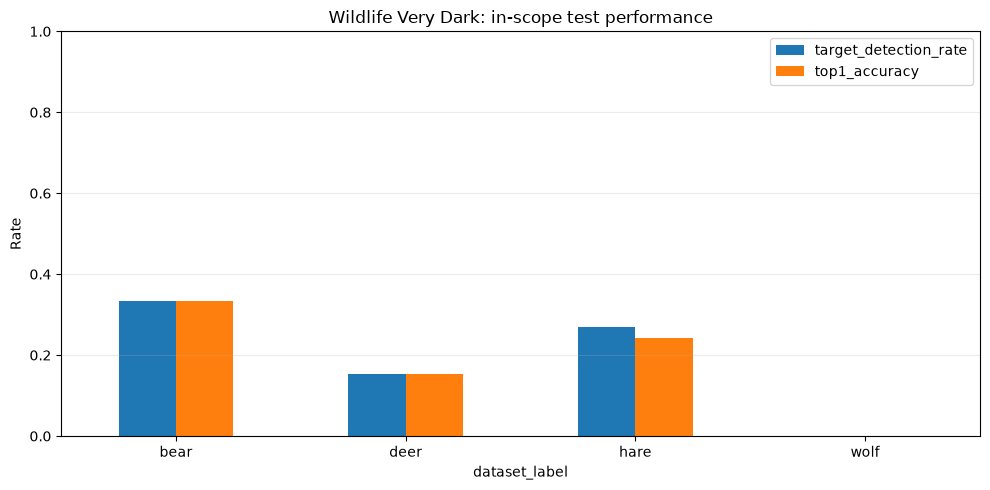

In [6]:
plot_df = per_label[['target_detection_rate', 'top1_accuracy']].sort_index()
ax = plot_df.plot.bar(figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title('Wildlife Very Dark: in-scope test performance')
ax.set_ylabel('Rate')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

In [7]:
errors = results_df.loc[~results_df['top1_correct'], [
    'file_name', 'dataset_label', 'top1_label', 'top1_confidence', 'target_detected'
]]
print(f'Top-1 errors: {len(errors)}')
display(errors.head(25))

Top-1 errors: 193


,file_name,dataset_label,top1_label,top1_confidence,target_detected
1,20000144.jpg,deer,NaN,NaN,False
2,20000364.jpg,deer,NaN,NaN,False
3,80000603.jpg,wolf,NaN,NaN,False
5,20000384.jpg,deer,elk,0.822081,False
7,80001219.jpg,wolf,NaN,NaN,False
9,10000486.jpg,bear,NaN,NaN,False
11,40000372.jpg,hare,NaN,NaN,False
13,20000380.jpg,deer,moose,0.772025,False
14,20000307.jpg,deer,moose,0.460861,False
15,40000819.jpg,hare,NaN,NaN,False
